In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [24]:
import numpy as np
import random

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

In [25]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [26]:
train_ds = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_ds = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

In [27]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [28]:
class OneConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2) # 32x32 -> 16x16
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32 * 16 * 16, 10)  # 32 канала * 16 * 16, 10 классов
        
    def forward(self, x):
        x = self.conv(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.fc(x)
        return x

In [29]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство для вычислений:', device)
if device.type == 'cuda':
    print('Видеокарта:', torch.cuda.get_device_name(0))

model = OneConvNet().to(device)
print(model)
print(f"Параметров: {sum(p.numel() for p in model.parameters()):,}")

OneConvNet(
  (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=8192, out_features=10, bias=True)
)
Параметров: 82,826


In [30]:
criterion = nn.CrossEntropyLoss()
#optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
optimizer = optim.SGD(model.parameters(), lr=0.01)

In [31]:
def evaluate(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return loss_sum / total, correct / total

Эпоха 1: train_loss=1.834, test_loss=1.697, test_acc=41.08%
Эпоха 2: train_loss=1.624, test_loss=1.560, test_acc=46.39%
Эпоха 3: train_loss=1.510, test_loss=1.467, test_acc=49.52%
Эпоха 4: train_loss=1.421, test_loss=1.409, test_acc=50.56%
Эпоха 5: train_loss=1.353, test_loss=1.340, test_acc=53.17%
Эпоха 6: train_loss=1.303, test_loss=1.310, test_acc=54.00%
Эпоха 7: train_loss=1.263, test_loss=1.275, test_acc=55.14%
Эпоха 8: train_loss=1.232, test_loss=1.252, test_acc=56.07%
Эпоха 9: train_loss=1.205, test_loss=1.248, test_acc=56.30%
Эпоха 10: train_loss=1.182, test_loss=1.253, test_acc=55.04%
Эпоха 11: train_loss=1.162, test_loss=1.211, test_acc=57.29%
Эпоха 12: train_loss=1.142, test_loss=1.218, test_acc=57.68%
Эпоха 13: train_loss=1.126, test_loss=1.200, test_acc=57.44%
Эпоха 14: train_loss=1.110, test_loss=1.177, test_acc=58.79%
Эпоха 15: train_loss=1.092, test_loss=1.157, test_acc=59.60%
Эпоха 16: train_loss=1.078, test_loss=1.148, test_acc=59.78%
Эпоха 17: train_loss=1.063, test_

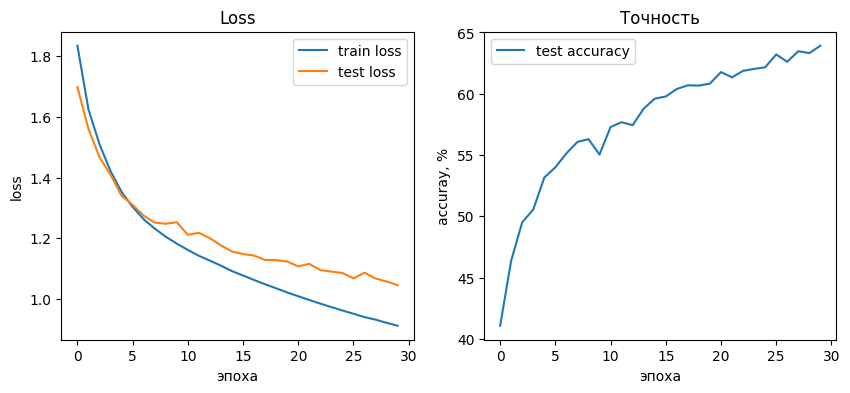

In [32]:
# --- Обучение на 10 эпох ---
epochs = 30
train_losses, test_losses, test_accs = [], [], []

for ep in range(epochs):
    model.train()
    total, n = 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * xb.size(0)
        n += xb.size(0)
    train_loss = total / n
    test_loss, test_acc = evaluate(model, test_dl)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    test_accs.append(test_acc)
    print(f"Эпоха {ep+1}: train_loss={train_loss:.3f}, test_loss={test_loss:.3f}, test_acc={test_acc*100:.2f}%")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train loss')
plt.plot(test_losses, label='test loss')
plt.xlabel('эпоха'); plt.ylabel('loss'); plt.legend(); plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot([a*100 for a in test_accs], label='test accuracy')
plt.xlabel('эпоха'); plt.ylabel('accuray, %'); plt.legend(); plt.title('Точность')
plt.show()

In [33]:
print(f"Итоговая точность на тесте: {test_accs[-1]*100:.2f}%")

Итоговая точность на тесте: 63.92%
